In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

La obra de una conducción en zona rural tiene su declaración de impacto ambiental (DIA) y su autorización; el acceso de los camiones de materiales y tierras se hace por la **pista de obra evaluada**, de 15 km, que rodea una zona especial de conservación (ZEC) de la Red Natura 2000. El cuadro de prelaciones, las duraciones (semanas), las toneladas que cada actividad mueve por la pista (`toneladas_acarreo`) y las semanas que se ahorrarían en cada una con una **pista corta** de 3 km a través de la ZEC (`semanas_menos_pista_corta`) se adjuntan.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, toneladas_acarreo, semanas_menos_pista_corta
    ('A'     , '---'      , 2       , 0                , 0                        ),
    ('B'     , '---'      , 4       , 1400             , 1                        ),
    ('C'     , '---'      , 5       , 0                , 0                        ),
    ('D'     , 'A,B'      , 6       , 3000             , 1                        ),
    ('E'     , 'A'        , 4       , 2500             , 1                        ),
    ('F'     , 'D,E'      , 1       , 0                , 0                        ),
    ('G'     , 'C,F'      , 6       , 0                , 0                        ),
    ('H'     , 'D'        , 4       , 500              , 1                        ),
], columns=['activity', 'predecessor', 'duration', 'toneladas_acarreo', 'semanas_menos_pista_corta']).set_index('activity')
datos_enunciado

,predecessor,duration,toneladas_acarreo,semanas_menos_pista_corta
activity,,,,
A,---,2,0,0
B,---,4,1400,1
C,---,5,0,0
D,"A,B",6,3000,1
E,A,4,2500,1
F,"D,E",1,0,0
G,"C,F",6,0,0
H,D,4,500,1


Transporte: 0.12 €/t·km y 0.1 kg CO₂/t·km. Cada semana de obra cuesta 8 k€ (instalaciones, maquinaria, equipo técnico) y emite 2.0 t CO₂. Restaurar la pista corta al terminar costaría 20 k€; la medida compensatoria que el órgano ambiental exigiría si la autorizara, unos 90 k€. Modificar el proyecto evaluado para incluir la pista corta exigiría una evaluación de la modificación que la empresa estima en **18 semanas** antes de poder abrirla. Precio sombra del carbono de la organización: 150 €/t.

> **De: Director de obra**
> Abrimos la pista corta por la ZEC: son 12 km menos por viaje y 2 semana(s) menos de obra. Al acabar restauramos el trazado (20 k€) y, si el órgano ambiental se pone serio, se paga la medida compensatoria; con los camiones y las semanas sale a cuenta. Lo de la evaluación de la modificación lo dejamos para la documentación final.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S18 — Alternativas antes que compensación en la Red Natura 2000.** Un proyecto o una modificación que pueda afectar de forma apreciable a un espacio de la Red Natura 2000 se somete a una adecuada evaluación de sus repercusiones y sólo se autoriza si no perjudica la integridad del lugar; con conclusiones negativas, las medidas compensatorias sólo caben a falta de soluciones alternativas y por razones imperiosas de interés público de primer orden. Si existe una alternativa (la que el proyecto evaluado ya tenía), la opción que daña el lugar no se autoriza aunque se ofrezca restaurar o compensar: en la pirámide, evitar está por encima de restaurar y de compensar, y aquí la norma lo exige. *(cf. Ley 42/2007, art. 46.4 y 46.5; Ley 21/2013, art. 7.2.c) (modificaciones de proyectos evaluados); PMBOK 8 §3.7 (figura 3-7).)*
- **S17 — Actividades exigidas por una norma: tienen duración y van en el cronograma.** Un trámite o trabajo que la norma exige antes de otro (un plan de trabajo aprobado por la autoridad laboral, la retirada de un material peligroso por una empresa inscrita, la evaluación de una modificación del proyecto) es una actividad del cronograma con su duración legal y su prelación. Omitirla no acorta el proyecto: lo deja sin autorización. Cuántas semanas de retraso causa y con cuánta antelación habría que lanzarla lo dice el calendario (lección 05), y es una cuenta, no una opinión (cf. C7 de la lección 19). *(cf. RD 396/2006, arts. 11, 12.2 y 17.1; Ley 21/2013, art. 7.2.c); PMBOK 8 §3.7.3 (dominio del cronograma).)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*
- **S2 — Externalidad internalizada.** Cuando la organización ha fijado un precio para una externalidad (precio sombra del carbono, canon, tasa), toda decisión de planificación —comprimir, comprar, diseñar— se compara por el coste total: coste del proyecto más el valor de la externalidad a ese precio. Con el precio fijado, la alternativa correcta es la de menor coste total, y comprar compensaciones a un precio inferior no cambia la cuenta. *(cf. PMBOK 8 §3.7 (estrategias para abordar las externalidades); LCSP art. 148.2 (externalidades medioambientales monetizables); precio sombra del carbono del BEI.)*
- **Norma o dato de referencia — cualquier plan, programa o proyecto que pueda afectar de forma apreciable a un espacio de la Red Natura 2000 se somete a una adecuada evaluación de sus repercusiones y sólo se autoriza tras asegurarse de que no causará perjuicio a la integridad del lugar; si, pese a conclusiones negativas y a falta de soluciones alternativas, debe realizarse por razones imperiosas de interés público de primer orden, se adoptan medidas compensatorias. Modificar un proyecto ya evaluado de modo que pueda tener efectos adversos significativos exige, como mínimo, evaluación simplificada** *(Ley 42/2007, art. 46.4 y 46.5; Ley 21/2013, art. 7.2.c).)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Calcule la duración del proyecto con la pista evaluada y con la pista corta, el coste y las emisiones del transporte por cada una, y el ahorro de la pista corta (semanas al coste semanal más transporte) frente al coste de restaurarla. Compare el coste total de las dos opciones al precio sombra.  "
pregunta_2 = "2. (A) Si la pista corta sólo pudiera abrirse tras una evaluación de la modificación de 18 semanas (las actividades de acarreo no empiezan antes), ¿cuánto dura el proyecto? Añada esa actividad previa al cuadro, recalcule el calendario y compare con el plan evaluado.  "
pregunta_3 = "3. (B) Según el criterio y la norma de referencia, ¿puede autorizarse la pista por la ZEC con la restauración y una medida compensatoria existiendo la pista evaluada? ¿Es la evaluación de la modificación un trámite «para la documentación final» o una actividad del cronograma? ¿En qué escalón de la pirámide queda cada opción?  "
pregunta_4 = "4. (C) ¿Qué propone al director de obra y qué comunica al cliente y al órgano ambiental? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule la duración del proyecto con la pista evaluada y con la pista corta, el coste y las emisiones del transporte por cada una, y el ahorro de la pista corta (semanas al coste semanal más transporte) frente al coste de restaurarla. Compare el coste total de las dos opciones al precio sombra.  

2. (A) Si la pista corta sólo pudiera abrirse tras una evaluación de la modificación de 18 semanas (las actividades de acarreo no empiezan antes), ¿cuánto dura el proyecto? Añada esa actividad previa al cuadro, recalcule el calendario y compare con el plan evaluado.  

3. (B) Según el criterio y la norma de referencia, ¿puede autorizarse la pista por la ZEC con la restauración y una medida compensatoria existiendo la pista evaluada? ¿Es la evaluación de la modificación un trámite «para la documentación final» o una actividad del cronograma? ¿En qué escalón de la pirámide queda cada opción?  

4. (C) ¿Qué propone al director de obra y qué comunica al cliente y al órgano ambiental? Aplique la rúbrica.  

# Resolución

In [6]:
km_larga, km_corta, coste_semana, emisiones_semana, coste_restaurar, medida_compensatoria, semanas_evaluacion, precio_sombra = 15, 3, 8, 2.0, 20, 90, 18, 150
coste_camion, factor_camion = 0.12, 0.1
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
acarreo = sorted(datos_proyecto.index[datos_proyecto['toneladas_acarreo'] > 0])
duraciones_corta = datos_proyecto['duration'] - datos_proyecto['semanas_menos_pista_corta']
duracion_corta = int(proyecto.duration(duraciones_corta))
toneladas = float(datos_proyecto['toneladas_acarreo'].sum())

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

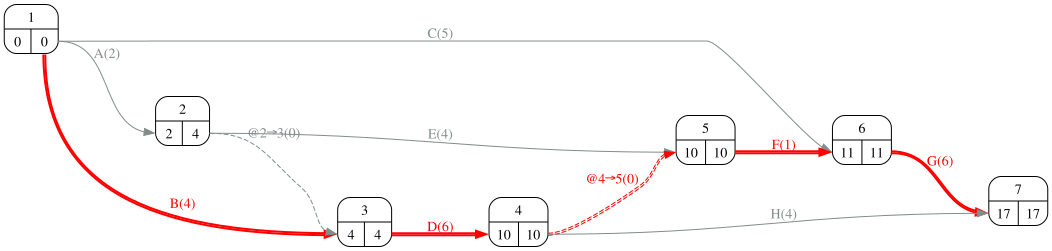

In [8]:
#| fig-cap: "Grafo PERT con la pista evaluada"
#| label: fig-pert
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Calcule la duración del proyecto con la pista evaluada y con la pista corta, el coste y las emisiones del transporte por cada una, y el ahorro de la pista corta (semanas al coste semanal más transporte) frente al coste de restaurarla. Compare el coste total de las dos opciones al precio sombra.  

In [10]:
#| tbl-cap: "Las dos pistas: duración, transporte, restauración y emisiones"
#| label: tbl-pistas
def opcion(km, semanas, restaurar):
    s = pd.Series({'duración (semanas)': semanas, 'transporte (k€)': toneladas * km * coste_camion / 1000,
                   'semanas de obra (k€)': semanas * coste_semana, 'restauración (k€)': restaurar,
                   'emisiones del transporte, alcance 3 (t CO₂)': toneladas * km * factor_camion / 1000,
                   'emisiones de las semanas de obra (t CO₂)': semanas * emisiones_semana})
    s['coste monetario (k€)'] = s['transporte (k€)'] + s['semanas de obra (k€)'] + s['restauración (k€)']
    s['emisiones (t CO₂)'] = s['emisiones del transporte, alcance 3 (t CO₂)'] + s['emisiones de las semanas de obra (t CO₂)']
    s['coste total al precio sombra (k€)'] = s['coste monetario (k€)'] + s['emisiones (t CO₂)'] * precio_sombra / 1000
    return s
comparacion = pd.DataFrame({'pista evaluada': opcion(km_larga, duracion, 0), 'pista corta por la ZEC': opcion(km_corta, duracion_corta, coste_restaurar)})
display(comparacion.round(2))
camino_c = ' / '.join('–'.join(r) for r in proyecto.critical_path(duraciones_corta).values())
ahorro = comparacion.loc['coste monetario (k€)', 'pista evaluada'] - comparacion.loc['coste monetario (k€)', 'pista corta por la ZEC']
Markdown(f'''La pista corta acorta el proyecto de {duracion} a **{duracion_corta}** semanas (ruta crítica {camino_c}) y, restauración incluida, ahorra **{ahorro:.1f} k€** en dinero y {comparacion.loc['emisiones (t CO₂)', 'pista evaluada'] - comparacion.loc['emisiones (t CO₂)', 'pista corta por la ZEC']:.1f} t: al precio sombra, {comparacion.loc['coste total al precio sombra (k€)', 'pista evaluada'] - comparacion.loc['coste total al precio sombra (k€)', 'pista corta por la ZEC']:.1f} k€. Ese es el tamaño de la tentación; la pregunta B es si está en la tabla.''')

,pista evaluada,pista corta por la ZEC
duración (semanas),17.00,15.00
transporte (k€),13.32,2.66
semanas de obra (k€),136.00,120.00
restauración (k€),0.00,20.00
"emisiones del transporte, alcance 3 (t CO₂)",11.10,2.22
emisiones de las semanas de obra (t CO₂),34.00,30.00
coste monetario (k€),149.32,142.66
emisiones (t CO₂),45.10,32.22
coste total al precio sombra (k€),156.08,147.50


La pista corta acorta el proyecto de 17 a **15** semanas (ruta crítica B–D–F–G) y, restauración incluida, ahorra **6.7 k€** en dinero y 12.9 t: al precio sombra, 8.6 k€. Ese es el tamaño de la tentación; la pregunta B es si está en la tabla.

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. (A) Si la pista corta sólo pudiera abrirse tras una evaluación de la modificación de 18 semanas (las actividades de acarreo no empiezan antes), ¿cuánto dura el proyecto? Añada esa actividad previa al cuadro, recalcule el calendario y compare con el plan evaluado.  

In [12]:
#| tbl-cap: "Calendario con la evaluación de la modificación (Z) antes de las actividades de acarreo"
#| label: tbl-evaluacion
datos_ev = datos_proyecto[['predecessor']].copy()
datos_ev['duration'] = duraciones_corta
datos_ev.loc['Z'] = ['---', semanas_evaluacion]
for a in acarreo:
    datos_ev.loc[a, 'predecessor'] = 'Z' if datos_ev.loc[a, 'predecessor'] == '---' else datos_ev.loc[a, 'predecessor'] + ',Z'
datos_ev['duration'] = datos_ev['duration'].astype(int)
prelaciones_ev = PredecessorTable.from_dataframe_of_strings(datos_ev, activity='activity', predecessor='predecessor')
proyecto_ev = prelaciones_ev.create_project()
calendario_ev = proyecto_ev.calendar(datos_ev['duration'])
duracion_ev = int(proyecto_ev.duration(datos_ev['duration']))
display(calendario_ev)
camino_ev = ' / '.join('–'.join(r) for r in proyecto_ev.critical_path(datos_ev['duration']).values())
Markdown(f'''Con la evaluación de la modificación ({semanas_evaluacion} semanas) antes del primer acarreo, el proyecto con la pista corta dura **{duracion_ev}** semanas (ruta crítica {camino_ev}): **{duracion_ev - duracion}** más que con la pista evaluada, {(duracion_ev - duracion) * coste_semana} k€ de coste indirecto. La pista que ahorraba {duracion - duracion_corta} semana(s) cuesta {duracion_ev - duracion} si se hace como la ley manda; y si no, no se puede hacer.''')

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,19,2,21,16,16,19,2
B,18,18,21,21,0,0,0,3
C,0,22,5,27,22,22,22,5
D,21,21,26,26,0,0,0,5
E,18,23,21,26,5,2,5,3
F,26,26,27,27,0,0,0,1
G,27,27,33,33,0,0,0,6
H,26,30,29,33,4,4,4,3
Z,0,0,18,18,0,0,0,18


Con la evaluación de la modificación (18 semanas) antes del primer acarreo, el proyecto con la pista corta dura **33** semanas (ruta crítica B–D–F–G–Z): **16** más que con la pista evaluada, 128 k€ de coste indirecto. La pista que ahorraba 2 semana(s) cuesta 16 si se hace como la ley manda; y si no, no se puede hacer.

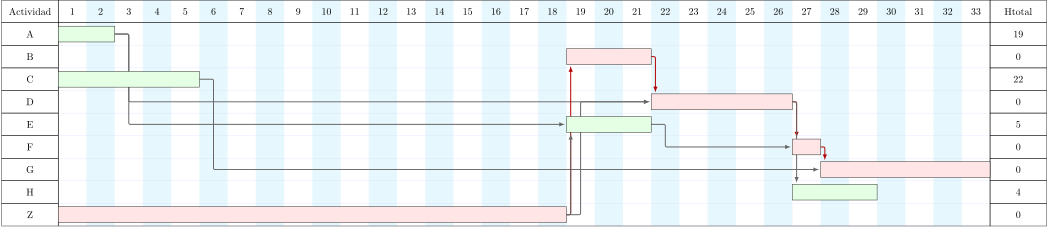

In [13]:
#| fig-cap: "Gantt con la evaluación de la modificación delante de los acarreos"
#| label: fig-ganttEv
_g, _dibujo = proyecto_ev.copy().gantt(datos_ev, 'duration', holguras=True, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_dibujo)

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. (B) Según el criterio y la norma de referencia, ¿puede autorizarse la pista por la ZEC con la restauración y una medida compensatoria existiendo la pista evaluada? ¿Es la evaluación de la modificación un trámite «para la documentación final» o una actividad del cronograma? ¿En qué escalón de la pirámide queda cada opción?  

**Norma y S18.** La pista corta afecta a un espacio de la Red Natura 2000: exige una adecuada evaluación de sus repercusiones (Ley 42/2007, art. 46.4) y sólo podría autorizarse si no perjudica la integridad del lugar; con conclusiones negativas, la medida compensatoria del art. 46.5 sólo cabe **a falta de soluciones alternativas** y por razones imperiosas de interés público de primer orden. La alternativa existe —es la pista evaluada, de 15 km, que ya está en el proyecto— y 2 semana(s) de obra no son una razón imperiosa de interés público: la pista por la ZEC **no es autorizable**, ni con restauración ni con los 90 k€ de compensación, y abrirla sin más es incumplir la DIA (Ley 21/2013, art. 55.3.c). **S17.** La evaluación de la modificación no es «documentación final»: es una actividad con duración (18 semanas) y prelación (antes del primer acarreo), y el apartado 2 muestra que el proyecto duraría 33 semanas en vez de 17: la pista corta, hecha legalmente, es más lenta. **S1.** Pista corta más restauración es **restaurar**; con medida compensatoria, **compensar**; la pista evaluada **evita** el impacto, y aquí evitar no es sólo el escalón más alto: es el único que la norma admite. **S2.** El coste total al precio sombra del apartado 1 informa, pero no decide: la respuesta B no depende de que la pista corta ahorre 6.7 k€.

In [15]:
preguntas_test = [
    ('En un espacio de la Red Natura 2000, las medidas compensatorias de un proyecto con conclusiones negativas en su evaluación sólo caben…', ['a falta de soluciones alternativas y por razones imperiosas de interés público de primer orden', 'si el promotor restaura el lugar al terminar', 'si el ahorro del proyecto supera el coste de la medida', 'siempre que las apruebe la dirección facultativa'],
     'S18: Ley 42/2007, art. 46.5.'),
    ('Abrir una pista de obra no prevista en el proyecto evaluado, a través de una ZEC, sin evaluar la modificación es…', ['incumplir las condiciones de la DIA: infracción grave', 'correcto si se restaura al final', 'correcto si se documenta al cierre', 'una decisión del jefe de obra'],
     'Ley 21/2013, arts. 7.2.c) y 55.3.c).'),
    ('Un trámite que la norma exige antes de una actividad (evaluar una modificación, aprobar un plan de trabajo) es, para el cronograma…', ['una actividad con su duración y su prelación: se calcula su efecto en el plazo', 'documentación que se adjunta al cierre', 'un riesgo que se acepta', 'una holgura'],
     'S17: omitirla no acorta el proyecto; lo deja sin autorización.'),
    ('Elegir la pista evaluada que rodea la ZEC en lugar de cruzarla y restaurar después es, en la pirámide…', ['evitar', 'restaurar', 'compensar', 'minimizar'],
     'S1: evitar el impacto es el escalón más deseable, y aquí el exigido.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — pista de obra')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
from pmule import muestra_test
muestra_test(preguntas_test)

$CATEGORY: Sostenibilidad 20 — pista de obra

::Sostenibilidad 20 — pista de obra P1::En un espacio de la Red Natura 2000, las medidas compensatorias de un proyecto con conclusiones negativas en su evaluación sólo caben… {=a falta de soluciones alternativas y por razones imperiosas de interés público de primer orden ~si el promotor restaura el lugar al terminar ~si el ahorro del proyecto supera el coste de la medida ~siempre que las apruebe la dirección facultativa ####S18: Ley 42/2007, art. 46.5.}

::Sostenibilidad 20 — pista de obra P2::Abrir una pista de obra no prevista en el proyecto evaluado, a través de una ZEC, sin evaluar la modificación es… {~una decisión del jefe de obra =incumplir las condiciones de la DIA: infracción grave ~correcto si se documenta al cierre ~correcto si se restaura al final ####Ley 21/2013, arts. 7.2.c) y 55.3.c).}

::Sostenibilidad 20 — pista de obra P3::Un trámite que la norma exige antes de una actividad (evaluar una modificación, aprobar un plan de tr

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director de obra y qué comunica al cliente y al órgano ambiental? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de obra: la tabla del apartado 1 con la tentación cuantificada y la del apartado 2 con lo que costaría hacerla legalmente (16 semanas más); y lo que sí puede hacerse por la pista evaluada: mejorar su firme para subir la velocidad de los camiones, cargar a plena capacidad, reordenar los acarreos con la nivelación (lección 11) o recuperar 2 semana(s) con Ackoff en otras actividades críticas (lección 10), con su coste. Al cliente: por qué la pista corta no está en la tabla y cuánto cuesta cada semana por la vía legal. Al órgano ambiental: nada que consultar si se respeta la DIA; si se quisiera otra pista, la modificación con su evaluación, antes. Prueba de publicidad: ¿explicaría al Seprona y a la prensa local la pista de 3 km por la ZEC como «la restauramos al acabar»?